In [1]:
import numpy as np
import statistics
import numpy as np
import pandas as pd
from abc import ABC, abstractmethod
import matplotlib.pyplot as plt


In [2]:
years = np.array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024])
Kampala_population = np.array([1200, 1250, 1300, 1350, 1420,1500, 1580, 1650, 1720, 1800])

In [3]:
class DistrictPopulation:

    def __init__(self, DistrictName, years, populations):
        self.DistrictName = DistrictName
        self.years = np.array(years)
        self.populations = np.array(populations)
        if len(self.years) != len(self.populations):
            raise ValueError("Years and populations must have equal lengths.")

        if len(self.years) == 0:
            raise ValueError("The data cannot be empty.")

        if np.any(self.populations < 0):
            raise ValueError("Population values cannot be negative.")
        if not np.all(np.isfinite(self.years)):
            raise ValueError("Years must be finite numbers.")

        if not np.all(self.years == self.years.astype(int)):
            raise ValueError("Years must be whole numbers.")

        if len(np.unique(self.years)) != len(self.years):
            raise ValueError("Years must be unique.")

        if not np.all(np.diff(self.years) > 0):
            raise ValueError("Years must be in ascending order.")

    def __len__(self) -> int:
        return len(self.populations)

    def __repr__(self) -> str:
        return (
            f"DistrictPopulation(name={self.DistrictName!r}, "
            f"years={len(self.years)}, "
            f"period={self.years[0]}-{self.years[-1]})"
        )

In [4]:
kampala = DistrictPopulation(
    "Kampala", years, Kampala_population
)

print(kampala)
print(len(kampala))

DistrictPopulation(name='Kampala', years=10, period=2015-2024)
10


In [5]:

Wakiso_population = np.array([950, 1000, 1070, 1150, 1220,1300, 1390, 1480, 1570, 1670])

Gulu_population = np.array([320, 330, 345, 360, 375,390, 410, 430, 455, 480])

Mbarara_population = np.array([400, 420, 440, 465, 490,520, 550, 580, 615, 650])

Mbale_population = np.array([480, 495, 515, 535, 555,580, 610, 640, 675, 710])

districts = {
    "Kampala": DistrictPopulation(
        "Kampala", years, Kampala_population
    ),
    "Wakiso": DistrictPopulation(
        "Wakiso", years, Wakiso_population
    ),
    "Gulu": DistrictPopulation(
        "Gulu", years, Gulu_population
    ),
    "Mbarara": DistrictPopulation(
        "Mbarara", years, Mbarara_population
    ),
    "Mbale": DistrictPopulation(
        "Mbale", years, Mbale_population
    )
}

print("Number of districts:", len(districts))
print(list(districts.keys()))


Number of districts: 5
['Kampala', 'Wakiso', 'Gulu', 'Mbarara', 'Mbale']


In [6]:
def descriptive_statistics(districts):
    results = []

    for name, district in districts.items():
        pop = district.populations
        pop_list = pop.astype(float).tolist()

        results.append({
            "District": name,
            "Mean (statistics)": statistics.mean(pop_list),
            "Mean (NumPy)": np.mean(pop),
            "Median (statistics)": statistics.median(pop_list),
            "Median (NumPy)": np.median(pop),
            "Variance (statistics)": statistics.variance(pop_list),
            "Variance (NumPy)": np.var(pop),
            "SD (statistics)": statistics.stdev(pop_list),
            "SD (NumPy)": np.std(pop)
        })

    return pd.DataFrame(results)

stats_table = descriptive_statistics(districts)
display(stats_table.round(2))


,District,Mean (statistics),Mean (NumPy),Median (statistics),Median (NumPy),Variance (statistics),Variance (NumPy),SD (statistics),SD (NumPy)
0,Kampala,1477.0,1477.0,1460.0,1460.0,42601.11,38341.00,206.40,195.81
1,Wakiso,1280.0,1280.0,1260.0,1260.0,60066.67,54060.00,245.09,232.51
2,Gulu,389.5,389.5,382.5,382.5,2885.83,2597.25,53.72,50.96
3,Mbarara,513.0,513.0,505.0,505.0,7184.44,6466.00,84.76,80.41
4,Mbale,579.5,579.5,567.5,567.5,6058.06,5452.25,77.83,73.84


In [7]:
##Population growth
def calculate_growth(districts):
    results = []
    annual_rates = {}

    for name, district in districts.items():
        pop = district.populations

        # Year-on-year growth rates (%)
        yoy = np.diff(pop) / pop[:-1] * 100
        annual_rates[name] = yoy

        # Compound Annual Growth Rate (%)
        cagr = ((pop[-1] / pop[0]) **
                (1 / (len(pop) - 1)) - 1) * 100

        results.append({
            "District": name,
            "CAGR (%)": cagr,
            "Mean YoY Growth (%)": np.mean(yoy),
            "Total Growth (%)": (pop[-1] / pop[0] - 1) * 100
        })

    return pd.DataFrame(results), annual_rates


growth_table, annual_rates = calculate_growth(districts)

display(growth_table.round(2))


,District,CAGR (%),Mean YoY Growth (%),Total Growth (%)
0,Kampala,4.61,4.61,50.00
1,Wakiso,6.47,6.47,75.79
2,Gulu,4.61,4.61,50.00
3,Mbarara,5.54,5.54,62.50
4,Mbale,4.45,4.45,47.92


In [8]:
for name, rates in annual_rates.items():
    print(f"{name}: {np.round(rates, 2)}")

Kampala: [4.17 4.   3.85 5.19 5.63 5.33 4.43 4.24 4.65]
Wakiso: [5.26 7.   7.48 6.09 6.56 6.92 6.47 6.08 6.37]
Gulu: [3.12 4.55 4.35 4.17 4.   5.13 4.88 5.81 5.49]
Mbarara: [5.   4.76 5.68 5.38 6.12 5.77 5.45 6.03 5.69]
Mbale: [3.12 4.04 3.88 3.74 4.5  5.17 4.92 5.47 5.19]


In [9]:
fastest = growth_table.loc[growth_table["CAGR (%)"].idxmax()]
print(f"Fastest-growing district: {fastest['District']}")
print(f"CAGR: {fastest['CAGR (%)']:.2f}%")

Fastest-growing district: Wakiso
CAGR: 6.47%


In [10]:
class Forecaster(ABC):
    """Abstract base class for population forecasting models."""

    def __init__(self):
        self.is_fitted = False

    @abstractmethod
    def fit(self, years, populations):
        """Fit the model to historical population data."""
        pass

    @abstractmethod
    def predict(self, horizon):
        """Predict population for the requested number of future years."""
        pass


In [11]:
class LinearTrendForecaster(Forecaster):
    """Forecast population using a fitted linear trend."""

    def fit(self, years, populations):
        years = np.asarray(years, dtype=float)
        populations = np.asarray(populations, dtype=float)

        if len(years) != len(populations) or len(years) < 2:
            raise ValueError("Provide at least two matching observations.")

        if not np.all(np.isfinite(years)) or not np.all(np.isfinite(populations)):
            raise ValueError("Inputs must be finite.")

        if np.any(populations < 0):
            raise ValueError("Populations cannot be negative.")

        self.coefficients = np.polyfit(years, populations, 1)
        self.last_year = years[-1]
        self.is_fitted = True
        return self

    def predict(self, horizon):
        if not self.is_fitted:
            raise RuntimeError("Fit the model before predicting.")

        if not isinstance(horizon, (int, np.integer)) or horizon < 1:
            raise ValueError("Horizon must be a positive integer.")

        future_years = self.last_year + np.arange(1, horizon + 1)
        return np.polyval(self.coefficients, future_years)


In [12]:
class ExponentialForecaster(Forecaster):
    """Forecast population using constant compound annual growth."""

    def fit(self, years, populations):
        years = np.asarray(years, dtype=float)
        populations = np.asarray(populations, dtype=float)

        if len(years) != len(populations) or len(years) < 2:
            raise ValueError("Provide at least two matching observations.")

        if not np.all(np.isfinite(years)) or not np.all(np.isfinite(populations)):
            raise ValueError("Inputs must be finite.")

        if np.any(populations <= 0):
            raise ValueError("Exponential growth requires positive populations.")

        if not np.all(np.diff(years) > 0):
            raise ValueError("Years must be in ascending order.")

        intervals = years[-1] - years[0]
        self.rate = (populations[-1] / populations[0]) ** (1 / intervals) - 1
        self.last_population = populations[-1]
        self.last_year = years[-1]
        self.is_fitted = True
        return self

    def predict(self, horizon):
        if not self.is_fitted:
            raise RuntimeError("Fit the model before predicting.")

        if not isinstance(horizon, (int, np.integer)) or horizon < 1:
            raise ValueError("Horizon must be a positive integer.")

        steps = np.arange(1, horizon + 1)
        return self.last_population * (1 + self.rate) ** steps


In [13]:
train_years = years[:7]
train_pop = districts["Kampala"].populations[:7]

linear = LinearTrendForecaster().fit(train_years, train_pop)
exponential = ExponentialForecaster().fit(train_years, train_pop)

print("Linear predictions:", np.round(linear.predict(3), 2))
print("Exponential predictions:", np.round(exponential.predict(3), 2))


Linear predictions: [1622.86 1685.71 1748.57]
Exponential predictions: [1654.13 1731.74 1812.99]


In [14]:
class FibonacciRatioForecaster(Forecaster):
    """Forecast by compounding successive Fibonacci-number ratios.

    This is an experimental benchmark, not an assumption that population
    genuinely grows according to Fibonacci ratios.
    """
    def fit(self, years, populations):
        years = np.asarray(years, dtype=float)
        populations = np.asarray(populations, dtype=float)

        if len(years) != len(populations) or len(years) < 2:
            raise ValueError("Provide at least two matching observations.")
        if not np.all(np.isfinite(years)) or not np.all(np.isfinite(populations)):
            raise ValueError("Inputs must be finite.")
        if np.any(populations <= 0):
            raise ValueError("Populations must be positive.")
        if not np.all(np.diff(years) > 0):
            raise ValueError("Years must be in ascending order.")

        # Fibonacci numbers chosen after the initial small ratios
        self.fibonacci = [13, 21, 34, 55, 89, 144, 233, 377, 610, 987]
        self.ratios = [
            self.fibonacci[i + 1] / self.fibonacci[i]
            for i in range(len(self.fibonacci) - 1)
        ]

        self.last_population = populations[-1]
        self.last_year = years[-1]
        self.is_fitted = True
        return self

    def predict(self, horizon):
        if not self.is_fitted:
            raise RuntimeError("Fit the model before predicting.")
        if not isinstance(horizon, (int, np.integer)) or horizon < 1:
            raise ValueError("Horizon must be a positive integer.")
        if horizon > len(self.ratios):
            raise ValueError("Horizon exceeds the available Fibonacci ratios.")

        predictions = []
        population = self.last_population

        for ratio in self.ratios[:horizon]:
            population = population * ratio
            predictions.append(population)

        return np.array(predictions)

In [15]:
fibonacci = FibonacciRatioForecaster().fit(train_years, train_pop)

print("Linear:", np.round(linear.predict(3), 2))
print("Exponential:", np.round(exponential.predict(3), 2))
print("Fibonacci:", np.round(fibonacci.predict(3), 2))

Linear: [1622.86 1685.71 1748.57]
Exponential: [1654.13 1731.74 1812.99]
Fibonacci: [2552.31 4132.31 6684.62]


In [16]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}


model_classes = {
    "Linear": LinearTrendForecaster,
    "Exponential": ExponentialForecaster,
    "Fibonacci": FibonacciRatioForecaster
}

results = []

for name, district in districts.items():
    train_years = district.years[:7]       # 2015–2021
    train_pop = district.populations[:7]
    test_pop = district.populations[7:]    # 2022–2024

    for model_name, model_class in model_classes.items():
        model = model_class().fit(train_years, train_pop)
        predictions = model.predict(3)
        metrics = calculate_metrics(test_pop, predictions)

        results.append({
            "District": name,
            "Model": model_name,
            **metrics
        })

metrics_table = pd.DataFrame(results)
display(metrics_table.round(2))

,District,Model,MAE,RMSE,MAPE (%)
0,Kampala,Linear,37.62,38.97,2.17
1,Kampala,Exponential,9.62,10.39,0.55
2,Kampala,Fibonacci,2733.08,3188.15,155.43
3,Wakiso,Linear,49.40,52.37,3.09
4,Wakiso,Exponential,6.80,8.05,0.42
5,Wakiso,Fibonacci,2347.18,2743.61,145.14
6,Gulu,Linear,18.57,20.29,4.01
7,Gulu,Exponential,9.44,10.87,2.02
8,Gulu,Fibonacci,701.41,818.35,150.36
9,Mbarara,Linear,20.71,22.27,3.31


In [17]:
# Select the model with the lowest MAPE for each district
best_models = (
    metrics_table.sort_values("MAPE (%)")
    .groupby("District", as_index=False)
    .first()
)

display(best_models.round(2))

# Forecast 2025–2029 using each district's selected model
future_years = np.arange(2025, 2030)
forecast_results = []
selected_forecasters = {}

for _, row in best_models.iterrows():
    district_name = row["District"]
    model_name = row["Model"]
    district = districts[district_name]

    model = model_classes[model_name]().fit(
        district.years,
        district.populations
    )

    predictions = model.predict(5)
    selected_forecasters[district_name] = model

    for year, prediction in zip(future_years, predictions):
        forecast_results.append({
            "District": district_name,
            "Year": year,
            "Forecast Population (thousands)": prediction
        })

forecast_table = pd.DataFrame(forecast_results)
display(forecast_table.round(2))

,District,Model,MAE,RMSE,MAPE (%)
0,Gulu,Exponential,9.44,10.87,2.02
1,Kampala,Exponential,9.62,10.39,0.55
2,Mbale,Exponential,13.92,15.59,2.02
3,Mbarara,Exponential,2.83,3.53,0.45
4,Wakiso,Exponential,6.80,8.05,0.42


,District,Year,Forecast Population (thousands)
0,Gulu,2025,502.12
1,Gulu,2026,525.26
2,Gulu,2027,549.46
3,Gulu,2028,574.78
4,Gulu,2029,601.27
5,Kampala,2025,1882.95
6,Kampala,2026,1969.72
7,Kampala,2027,2060.49
8,Kampala,2028,2155.44
9,Kampala,2029,2254.76


In [18]:
classroom_results = []

for name, district in districts.items():
    population_2024 = district.populations[-1] * 1000
    population_2029 = forecast_table.loc[
        (forecast_table["District"] == name) &
        (forecast_table["Year"] == 2029),
        "Forecast Population (thousands)"
    ].iloc[0] * 1000

    pupils_2024 = population_2024 * 0.18
    pupils_2029 = population_2029 * 0.18

    classrooms_2024 = np.ceil(pupils_2024 / 53)
    classrooms_2029 = np.ceil(pupils_2029 / 53)

    classroom_results.append({
        "District": name,
        "Estimated Pupils 2024": pupils_2024,
        "Estimated Pupils 2029": pupils_2029,
        "Classrooms Needed 2024": classrooms_2024,
        "Classrooms Needed 2029": classrooms_2029,
        "Additional Classrooms": classrooms_2029 - classrooms_2024
    })

classroom_table = pd.DataFrame(classroom_results)
display(classroom_table.round(0).astype({
    "Estimated Pupils 2024": int,
    "Estimated Pupils 2029": int,
    "Classrooms Needed 2024": int,
    "Classrooms Needed 2029": int,
    "Additional Classrooms": int
}))

,District,Estimated Pupils 2024,Estimated Pupils 2029,Classrooms Needed 2024,Classrooms Needed 2029,Additional Classrooms
0,Kampala,324000,405857,6114,7658,1544
1,Wakiso,300600,411241,5672,7760,2088
2,Gulu,86400,108229,1631,2043,412
3,Mbarara,117000,153224,2208,2892,684
4,Mbale,127800,158849,2412,2998,586


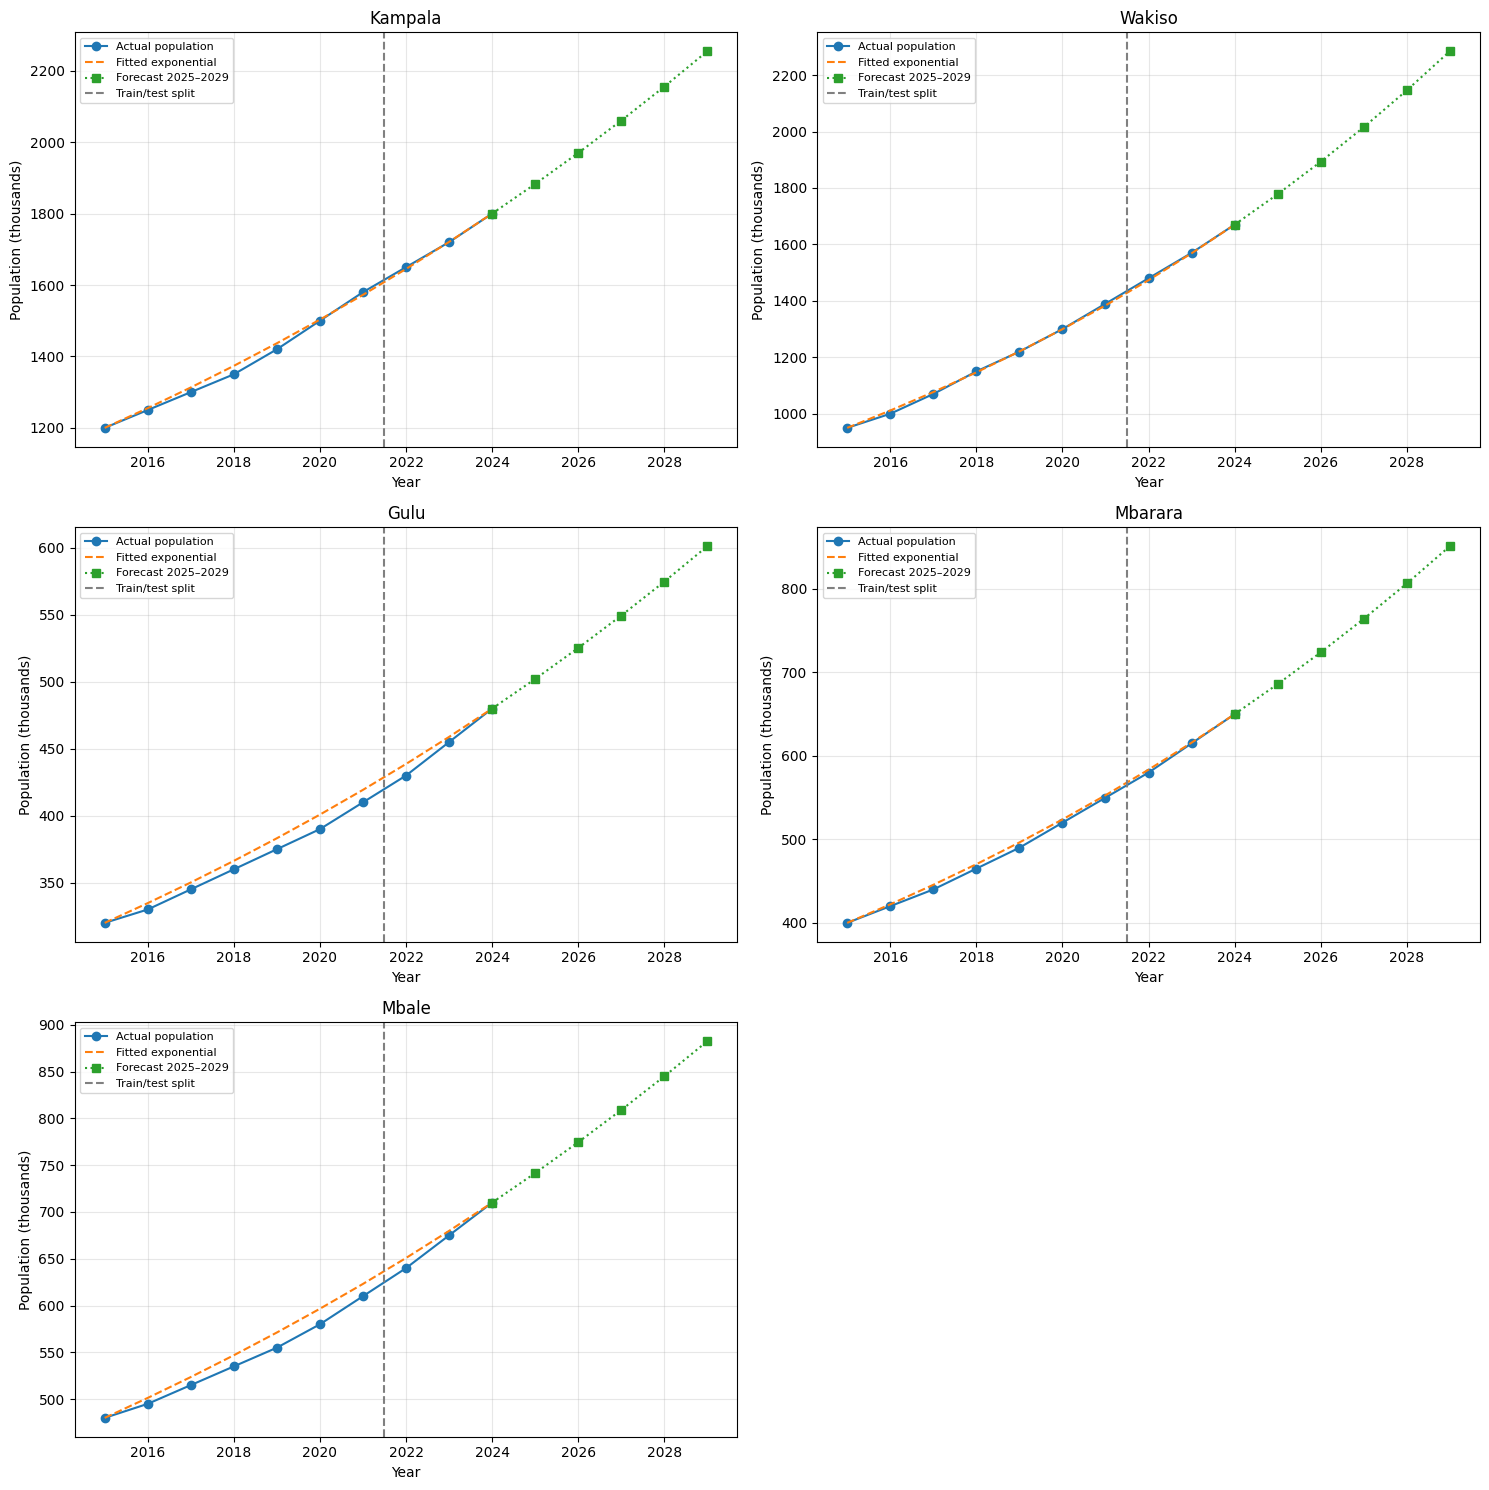

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, (name, district) in enumerate(districts.items()):
    ax = axes[i]
    model_name = best_models.loc[
        best_models["District"] == name, "Model"
    ].iloc[0]
    model = selected_forecasters[name]

    # Actual historical population
    ax.plot(
        district.years, district.populations,
        marker="o", label="Actual population"
    )

    # Fitted values where the model defines an in-sample curve
    if model_name == "Linear":
        fitted = np.polyval(model.coefficients, district.years)
        ax.plot(
            district.years, fitted, linestyle="--",
            label="Fitted trend"
        )
    elif model_name == "Exponential":
        fitted = model.last_population * (
            1 + model.rate
        ) ** (district.years - model.last_year)
        ax.plot(
            district.years, fitted, linestyle="--",
            label="Fitted exponential"
        )
    else:
        ax.text(
            0.03, 0.95,
            "Fitted historical curve not defined",
            transform=ax.transAxes, va="top", fontsize=8
        )

    # Five-year forecast
    predictions = model.predict(5)
    forecast_line_years = np.concatenate([[2024], future_years])
    forecast_line_values = np.concatenate([
        [district.populations[-1]], predictions
    ])

    ax.plot(
        forecast_line_years, forecast_line_values,
        marker="s", linestyle=":", label="Forecast 2025–2029"
    )

    # Mark the training/test boundary
    ax.axvline(2021.5, color="grey", linestyle="--",
               label="Train/test split")
    ax.set_title(name)
    ax.set_xlabel("Year")
    ax.set_ylabel("Population (thousands)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

# Remove the unused sixth subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

In [20]:
variance_results = []

for name, district in districts.items():
    forecast_values = forecast_table.loc[
        forecast_table["District"] == name,
        "Forecast Population (thousands)"
    ].to_numpy()

    actual_variance = np.var(district.populations)
    forecast_variance = np.var(forecast_values)

    variance_results.append({
        "District": name,
        "Actual Variance": actual_variance,
        "Forecast Variance": forecast_variance,
        "Variance Difference": forecast_variance - actual_variance
    })

variance_table = pd.DataFrame(variance_results)
display(variance_table.round(2))

,District,Actual Variance,Forecast Variance,Variance Difference
0,Kampala,38341.00,17286.15,-21054.85
1,Wakiso,54060.00,32105.09,-21954.91
2,Gulu,2597.25,1229.24,-1368.01
3,Mbarara,6466.00,3413.55,-3052.45
4,Mbale,5452.25,2483.37,-2968.88


In [21]:
rng = np.random.default_rng(42)
bootstrap_results = {}

for name, district in districts.items():
    train_years = district.years[:7]
    train_pop = district.populations[:7]
    model_name = best_models.loc[
        best_models["District"] == name, "Model"
    ].iloc[0]

    model = model_classes[model_name]().fit(train_years, train_pop)
    point_forecast = model.predict(5)

    # Obtain in-sample fitted values for residuals
    if model_name == "Linear":
        fitted_train = np.polyval(model.coefficients, train_years)
        residuals = train_pop - fitted_train
    elif model_name == "Exponential":
        fitted_train = model.last_population * (
            1 + model.rate
        ) ** (train_years - model.last_year)
        residuals = train_pop - fitted_train
    else:
        # Fibonacci ratios do not define an in-sample fitted curve.
        # Use one-step historical changes as a simple residual proxy.
        residuals = np.diff(train_pop) - np.mean(np.diff(train_pop))

    simulated_forecasts = []

    for _ in range(1000):
        sampled_errors = rng.choice(
            residuals, size=5, replace=True
        )
        simulated_forecasts.append(point_forecast + sampled_errors)

    simulated_forecasts = np.asarray(simulated_forecasts)

    lower = np.percentile(simulated_forecasts, 2.5, axis=0)
    upper = np.percentile(simulated_forecasts, 97.5, axis=0)

    bootstrap_results[name] = {
        "forecast": point_forecast,
        "lower": lower,
        "upper": upper
    }

    print(f"\n{name}")
    print("Forecast:", np.round(point_forecast, 2))
    print("95% lower:", np.round(lower, 2))
    print("95% upper:", np.round(upper, 2))


Kampala
Forecast: [1654.13 1731.74 1812.99 1898.05 1987.1 ]
95% lower: [1627.18 1704.79 1786.04 1871.1  1960.15]
95% upper: [1654.13 1731.74 1812.99 1898.05 1987.1 ]

Wakiso
Forecast: [1481.03 1578.02 1681.36 1791.47 1908.79]
95% lower: [1468.81 1565.8  1669.15 1779.25 1896.57]
95% upper: [1481.9  1578.89 1682.23 1792.34 1909.66]

Gulu
Forecast: [427.29 445.31 464.09 483.66 504.06]
95% lower: [423.8  441.81 460.59 480.16 500.56]
95% upper: [427.29 445.31 464.09 483.66 504.06]

Mbarara
Forecast: [579.98 611.59 644.93 680.09 717.16]
95% lower: [575.18 606.8  640.14 675.29 712.36]
95% upper: [579.98 611.59 644.93 680.09 717.16]

Mbale
Forecast: [634.86 660.73 687.66 715.69 744.85]
95% lower: [626.7  652.57 679.5  707.52 736.69]
95% upper: [634.86 660.73 687.66 715.69 744.85]


### Findings and Limitations

The analysis examined population trends in five districts between 2015 and 2024 and developed five-year forecasts for 2025–2029. Descriptive statistics summarised the central tendency and variability of each district's population, while year-on-year growth rates and compound annual growth rates (CAGR) helped compare population growth over time. The historical series showed an overall increase in population across the districts. However, the magnitude and rate of growth differed between districts.

Three forecasting approaches were evaluated: linear trend, exponential growth, and a Fibonacci-ratio model. Their predictive performance was compared using mean absolute error (MAE), root mean squared error (RMSE), and mean absolute percentage error (MAPE) on the 2022–2024 test period. The model with the lowest test-set MAPE was selected for each district and refitted using the full historical series to generate forecasts through 2029. The projections were also used to estimate potential primary-school classroom requirements, assuming that 18% of the population is primary-school age and each classroom accommodates 53 pupils.

Several limitations should be considered. The population data are synthetic and are used only to demonstrate the analytical methods; therefore, the forecasts are not official demographic estimates. The three-year test period provides limited evidence of future predictive performance. Linear and exponential models assume relatively stable patterns, while the Fibonacci-ratio model has no established demographic justification and may generate unrealistic values. The classroom estimates also exclude current classroom capacity, enrolment patterns, migration, and changes in the school-age population share. Future work should use verified UBOS population data and school-enrolment statistics, assess uncertainty carefully, and validate forecasts against longer historical periods.